# 17 · Guide: testing a new model against the ladder

The worked example is the entity-weighted model (`matching/entity_weighted.py`, X2 plus bounded concept coverage). Every stage that `fit(None)` normally hides is spelled out.

1. **Data**: the final set (the exam), the A2 `train` region (the study material), and the dev pools (where we tune).
2. **Model**, built stage by stage: extract concepts → fit IDF on train CVs → load the role model → assemble.
3. **Tune and score**: pick α on the dev pools, then define the scorer used for the 600 final-set pairs.
4. **Evaluate** the tuned model on the final set, once.
5. **Compare** with the committed ladder, with paired deltas.

Rules enforced here (`AGENTS.md`): nothing is fitted or tuned on the final set (D46); a model reads `text_v2` plus `jd_title` only (D53/D54); every figure carries *n* and a CI over JDs, with strata beside the total. A model scored here is **`exploratory`** (rule 8).

## Step 1 · Data: three populations, kept apart

| Population | Use | Labels |
|---|---|---|
| **Final set**, 600 pairs (60 JDs × 10 CVs), A2 `eval` region | scored on, never fitted on | frozen Fit / No Fit (D41) |
| **A2 `train` region** (157,688 CVs / 106,423 JDs) | fit anything: IDF counts, role model, weak pairs | none needed |
| **Dev pools** (400 JDs × 500 CVs, drawn from `train`) | tune hyperparameters (α) | proxy: same oracle role family, not human fit |

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from candidate_screener import reporting
from candidate_screener.evaluation import dev_pools, final_set, indomain, stage1
from candidate_screener.evaluation.shortlist_dev import recall_per_jd
from candidate_screener.matching import corpus

reporting.style(plt)
SEED, VARIANT = 0, stage1.TEXT_VARIANT            # "v2": the text a model may read (D53)

# 1a. Final set: labels go to the scorer only.
frame = final_set.load()
RULE_VERSION = int(frame.rule_version.iloc[0])
lab = indomain.labels(frame)
pairs = (corpus.a2_pairs(text_variant=VARIANT)
         .assign(keyword_match=lambda d: corpus.keyword_match(d))      # measurement only
         .set_index("pair_id").loc[lab.index].reset_index())
# What a model sees: ids, text and the JD title (D54). No CV Position, keyword or experience field.
final_inputs = pairs.assign(jd_title=pairs.jd_position)[["pair_id", "jd_id", "cv_id", "jd_text", "cv_text", "jd_title"]]
print(f"final set: {len(pairs)} pairs, {pairs.jd_id.nunique()} JDs, rule_version {RULE_VERSION}")

# 1b. Train region: the 20k-CV sample used for IDF / weak pairs (D19).
train_jd, train_cv = corpus.a2_train_documents(text_variant=VARIANT)
assert not set(train_cv.id) & set(pairs.cv_id) and not set(train_jd.id) & set(pairs.jd_id), "train overlaps the final set"
print(f"train sample: {len(train_cv):,} CVs, {len(train_jd):,} JDs; no id overlaps the 600 pairs")

# 1c. Dev pools: the tuning set. Its CVs are held out of the IDF population below.
dev = dev_pools.build()
dev_pairs = dev_pools.pairs(dev)
dev_rel = dev_pools.labels(dev, dev_pairs)
print(f"dev pools: {dev_pairs.jd_id.nunique()} JDs x {dev_pools.POOL_SIZE} CVs, splits {dev_pairs.split.value_counts().to_dict()}")

final set: 600 pairs, 60 JDs, rule_version 1
train sample: 20,000 CVs, 20,000 JDs; no id overlaps the 600 pairs


dev pools: 400 JDs x 500 CVs, splits {'dev-train': 125000, 'dev-select': 75000}


## Step 2 · Build the model, stage by stage

### 2a · Extraction: text → concepts
`ConceptExtractor` finds vocabulary skills (rule-based `SkillMatcher`) and keeps only **unqualified** mentions (a context rule drops "no experience with X"). A coverage score later asks: of the concepts the JD wants, how many does the CV hold?

In [2]:
from candidate_screener.matching.entity_weighted import ConceptExtractor, DocumentFrequency

extractor = ConceptExtractor()          # default: rules over the skill vocabulary

# To swap in GLiNER (notebook 13): pass a callable returning dicts with label, context_status, surface.
# extractor = ConceptExtractor(entities=my_gliner_fn)        # my_gliner_fn(text, side) -> list[dict]

row = final_inputs.iloc[0]
jd_c, cv_c = extractor.concepts(row.jd_text, "jd"), extractor.concepts(row.cv_text, "cv")
print("JD concepts:", sorted(jd_c)[:12])
print("CV concepts:", sorted(cv_c)[:12])
print("held by both:", sorted(jd_c & cv_c)[:12])

JD concepts: ['jira', 'kanban']
CV concepts: ['jira', 'learning management systems']
held by both: ['jira']


### 2b · Fit the IDF on train CVs
A concept every CV has says little; a rare one says a lot. `DocumentFrequency.fit` counts, per concept, how many **train** CVs mention it and weights it `1 + log((N+1)/(df+1))`, capped at 5 (unknown phrases get 1). It refuses anything that is not train-region CV text, which is why passing the 600 pairs failed. The 20k sample minus every dev-pool CV is the population.

In [3]:
idf_docs = (train_cv[~train_cv.id.isin(dev["cv"].id)]
            .rename(columns={"cv_text": "text"})[["id", "text"]].assign(region="train", doc_type="cv"))
frequencies = DocumentFrequency(extractor).fit(idf_docs)
print(f"IDF fitted on {frequencies.n_documents:,} train CVs, {len(frequencies.df):,} distinct concepts")
common = frequencies.df.most_common(3); rare = sorted(frequencies.df.items(), key=lambda kv: kv[1])[:3]
print("common:", [(c, round(frequencies.weight(c), 2)) for c, _ in common])
print("rare:  ", [(c, round(frequencies.weight(c), 2)) for c, _ in rare])

IDF fitted on 18,721 train CVs, 554 distinct concepts
common: [('html', 2.9), ('CSS', 2.94), ('JavaScript', 2.96)]
rare:   [('Monte Carlo simulation', 5.0), ('social media marketing techniques', 5.0), ('identify customer requirements', 5.0)]


### 2c · The rule layer (X1) and the text term
`ExtractedRule` (X1) scores `2 × role_match + experience_compatible`. `role_match` comes from a role-family classifier **trained on the train region** and loaded from cache (retraining is out of scope here: `python -m candidate_screener.extraction.role_family --train`). Experience bands are extracted by rules. The text term is the same TF-IDF as the ladder, with its vectoriser fitted on train documents.

In [20]:
from candidate_screener.extraction import role_family
from candidate_screener.matching import lexical
from candidate_screener.matching.extracted import ExtractedRule

role_model = role_family.load_role_model()
rule = ExtractedRule(role_model=role_model)
print("role model fingerprint:", role_model.fingerprint)
rule.fit(None)                                   # only records provenance when a model is supplied
text_term = lexical.Tfidf(VARIANT); text_term.fit(None)   # vectoriser from the 20k train docs

role model fingerprint: 44b7fff54614


### 2d · Assemble: a cleaner class

`EntityWeightedX2` in the package has optional arguments that silently build defaults (`extractor`, `frequencies`, `rule`, `text_system`), a separate `extractor` that must match the one inside `frequencies`, a `weighted` ablation flag, and an α = 0 branch. The class below keeps the same maths with none of that:

- every dependency is **required** and already fitted when the model is built; `fit` only checks and records provenance;
- the extractor is taken from `frequencies.extractor`, so counting and coverage cannot disagree;
- α is a plain mixing weight, with no special case;
- `components()` (α-free) and `combine()` (α only) are separate, so tuning α is a cheap recombination.

`score = 2·role_match + experience_compatible + 0.999 · ((1−α)·tfidf_scaled + α·coverage)`. α = 0 is X2.

In [21]:
from candidate_screener.matching.base import BaseSystem
from candidate_screener.matching.role_filter import per_jd_minmax

TEXT_BAND = 0.999     # the text / coverage mix stays below 1, so it only reorders ties in the rule score


class ConceptCoverageX2(BaseSystem):
    """X1 (role + experience) plus a per-JD scaled mix of TF-IDF and weighted concept coverage."""
    rung, stage, can_explain = "EW", "entity-weighted lexical", True

    def __init__(self, rule, text_term, frequencies, alpha, use_title):
        super().__init__()
        if not 0.0 <= alpha <= 1.0:
            raise ValueError("alpha must be in [0, 1]")
        self.rule, self.text_term, self.frequencies = rule, text_term, frequencies
        self.extractor = frequencies.extractor          # one extractor for counting and coverage
        self.alpha, self.use_title = float(alpha), use_title
        self.name = f"concept-coverage X2 (alpha={alpha:g}, title={use_title})"

    def _fit(self, train):
        if train is not None:
            raise ValueError("everything is fitted before construction; fit takes train=None")
        if not self.frequencies.fitted:
            raise ValueError("fit the DocumentFrequency on train CVs first")
        self.trained_on = f"{self.rule.trained_on}; {self.text_term.trained_on}; concept IDF on train CVs"

    def components(self, pairs):
        """The four alpha-free terms, row-aligned with `pairs`."""
        x = pairs[["pair_id", "jd_id", "cv_id", "jd_text", "cv_text", "jd_title"]].copy()
        if self.use_title:
            x["jd_text"] = x.jd_title.fillna("").astype(str) + "\n" + x.jd_text
        c = self.rule.components(x).reset_index(drop=True)
        c["tfidf_scaled"] = per_jd_minmax(x.jd_id.to_numpy(), self.text_term.score(x).to_numpy())
        c["coverage"] = [self.frequencies.coverage(self.extractor.concepts(j, "jd"),
                                                   self.extractor.concepts(v, "cv"), True)
                         for j, v in zip(x.jd_text, x.cv_text)]
        return c

    @staticmethod
    def combine(c, alpha):
        return (2 * c.role_match.to_numpy() + c.experience_compatible.to_numpy()
                + TEXT_BAND * ((1 - alpha) * c.tfidf_scaled.to_numpy() + alpha * c.coverage.to_numpy()))

    def _score(self, pairs):
        return self.combine(self.components(pairs), self.alpha)

    def params(self):
        return self.text_term.params()


def build_model(alpha, use_title=True):
    m = ConceptCoverageX2(rule, text_term, frequencies, alpha, use_title)
    m.fit(None)
    return m


probe = build_model(alpha=0.5)
print(probe.name); print(probe.trained_on)
probe.components(final_inputs.head(5)).round(3)

concept-coverage X2 (alpha=0.5, title=True)
role-family classifier, A2 train region, text_v2 (P3); experience: rules, nothing fitted (P4); role model 44b7fff54614; IDF from 20k+20k A2 train-region documents (text_v2); concept IDF on train CVs


,role_match,experience_compatible,tfidf_scaled,coverage
0,0.994,1,1.000,0.411
1,0.000,1,0.000,0.000
2,0.000,1,0.033,0.589
3,0.953,1,0.173,0.411
4,0.940,1,0.339,0.411


**Regression check:** the rewrite must reproduce the package class exactly (same fitted objects, same pairs).

In [23]:
from candidate_screener.matching.entity_weighted import EntityWeightedX2

reference = EntityWeightedX2(0.5, True, True, extractor=extractor, frequencies=frequencies, rule=rule, text_system=text_term)
reference.fit(None)
sample = final_inputs.sample(200, random_state=SEED)
assert np.allclose(reference.score(sample).to_numpy(), probe.score(sample).to_numpy()), "rewrite differs from EntityWeightedX2"
print("identical to matching.entity_weighted.EntityWeightedX2 on 200 pairs")

identical to matching.entity_weighted.EntityWeightedX2 on 200 pairs


**Your own model instead?** Implement `matching.base.BaseSystem`: `_fit(train)` (learn from train-region data only) and `_score(pairs) -> array`, with `pairs` carrying `jd_text`, `cv_text` (and `jd_title`). Anything real belongs in `src/candidate_screener/matching/` with a test. Notebooks report models, they do not define them.

## Step 3 · Tune on the dev pools, then define the scorer

**Tuning never touches the 600 labelled pairs.** α is chosen on the `dev-select` pools by Recall@50, where relevance is "same oracle role family". That is a proxy for recruiter judgement, so a dev winner can still disappoint on the final set. Components do not depend on α, so they are computed once and recombined.

In [24]:
N_TUNE_JDS = 30                                  # raise for a tighter pick; cost grows linearly
sel = dev_pairs[dev_pairs.split == "dev-select"]
tune_jds = sorted(sel.jd_id.unique())[:N_TUNE_JDS]
tune = sel[sel.jd_id.isin(tune_jds)].reset_index(drop=True)
tune_rel = dev_rel.loc[tune.pair_id].to_numpy()
tune_in = tune[["pair_id", "jd_id", "cv_id", "jd_text", "cv_text", "jd_title"]]
print(f"tuning on {len(tune_jds)} dev-select JDs, {len(tune):,} pairs")

comp = probe.components(tune_in)

from candidate_screener.evaluation import resample
rows = []
for a in (0., .25, .5, .75, 1.):
    r50 = recall_per_jd(tune, ConceptCoverageX2.combine(comp, a), tune_rel, 50)
    lo, hi = resample.mean_ci(r50, seed=SEED)
    rows.append({"alpha": a, "recall@50": round(r50.mean(), 4), "ci": [round(lo, 3), round(hi, 3)], "n_jd": len(r50)})
sweep = pd.DataFrame(rows); print(sweep)
from candidate_screener.evaluation.entity_weighted import choose_alpha
ALPHA = choose_alpha({r["alpha"]: {"recall@50": r["recall@50"]} for r in rows})   # registered tie-break: earlier alpha
print("chosen alpha:", ALPHA)

tuning on 30 dev-select JDs, 15,000 pairs
   alpha  recall@50              ci  n_jd
0   0.00     0.6793  [0.572, 0.775]    30
1   0.25     0.6784   [0.574, 0.77]    30
2   0.50     0.6869   [0.583, 0.78]    30
3   0.75     0.6749  [0.567, 0.772]    30
4   1.00     0.6619  [0.559, 0.756]    30
chosen alpha: 0.5


The scorer for the final set is `indomain.rank_figures`: for each JD with both a Fit and a No Fit candidate, AUC (is a Fit ranked above a No Fit for the same job?), averaged over JDs with a CI resampling **JDs**; 0.5 is chance. `within_family_auc` restricts to candidates in the JD's role family. `llm_free` drops pairs whose label needed the LLM. `generic`, `targeted` and `total` always come together.

In [25]:
def evaluate_model(m, inputs=final_inputs):
    scores = m.score(inputs)                     # indexed by pair_id; raises on NaN / wrong length
    unscoreable = []
    figs = [f.as_dict() for f in indomain.rank_figures(m.name, scores, lab, pairs, RULE_VERSION, SEED, unscoreable)]
    indomain.assert_total_has_strata(figs)
    return scores, figs, unscoreable

## Step 4 · Evaluate on the final set (once)

In [ ]:
model = build_model(ALPHA)
scores, figs, unscoreable = evaluate_model(model)
mine = pd.DataFrame(figs)
print(mine[mine.subset == "all"].pivot(index="metric", columns="scope", values="value")[list(final_set.SCOPES)].round(3))
print("total AUC:", mine.query("metric=='auc' and scope=='total' and subset=='all'")[["ci_low", "ci_high", "n_jd", "n_pairs"]].round(3).to_dict("records")[0])
print("unscoreable:", unscoreable)
card = model.card(); print({k: card[k] for k in ("params", "ms_per_pair", "ms_per_500_candidate_role")})

scope              generic  targeted  total
metric                                     
auc                  0.860     0.820  0.847
within_family_auc    0.729     0.704  0.719
total AUC: {'ci_low': 0.804, 'ci_high': 0.886, 'n_jd': 59, 'n_pairs': 590}
unscoreable: []
{'params': 5000, 'ms_per_pair': 7.1352, 'ms_per_500_candidate_role': 3567.6}


: 

## Step 5 · Compare against the other models

The committed record holds every rung (rebuilt by `uv run python -m candidate_screener.evaluation.stage1`). Overlapping CIs are a coarse screen; the way to claim a win is the **paired per-JD delta** below.

In [10]:
record = json.loads(stage1.RECORD.read_text(encoding="utf-8"))
assert record["reference"]["rule_version"] == RULE_VERSION, "record and final set differ"

def row(name, status, f):
    return {"system": name, "status": status, "generic": f[("auc", "generic")]["value"], "targeted": f[("auc", "targeted")]["value"],
            "total": f[("auc", "total")]["value"], "lo": f[("auc", "total")]["ci_low"], "hi": f[("auc", "total")]["ci_high"],
            "within-family": f[("within_family_auc", "total")]["value"]}

rows = [row(n, b["status"], {(x["metric"], x["scope"]): x for x in b["figures"] if x["subset"] == "all"})
        for n, b in record["systems"].items()]
rows.append(row(f"► {model.name}", "exploratory", {(x["metric"], x["scope"]): x for x in figs if x["subset"] == "all"}))
table = pd.DataFrame(rows).sort_values("total", ascending=False).reset_index(drop=True)
table.round(3)

,system,status,generic,targeted,total,lo,hi,within-family
0,extracted rule + SBERT (weak fine-tuned),held-out,0.891,0.785,0.855,0.817,0.890,0.735
1,extracted rule + TF-IDF,held-out,0.863,0.826,0.850,0.809,0.889,0.745
2,"► concept-coverage X2 (alpha=0.5, title=True)",exploratory,0.860,0.820,0.847,0.804,0.886,0.719
3,metadata + TF-IDF,oracle,0.843,0.851,0.846,0.799,0.888,0.697
4,SBERT (weak fine-tuned),exploratory,0.853,0.796,0.834,0.796,0.870,0.752
5,extracted rule + skill overlap,held-out,0.851,0.761,0.821,0.767,0.869,0.704
6,extracted rule,held-out,0.851,0.755,0.818,0.765,0.867,0.678
7,TF-IDF,exploratory,0.780,0.807,0.789,0.741,0.835,0.714
8,metadata rules,oracle,0.776,0.784,0.778,0.732,0.819,0.540
9,SBERT (zero-shot),exploratory,0.740,0.731,0.737,0.686,0.784,0.731


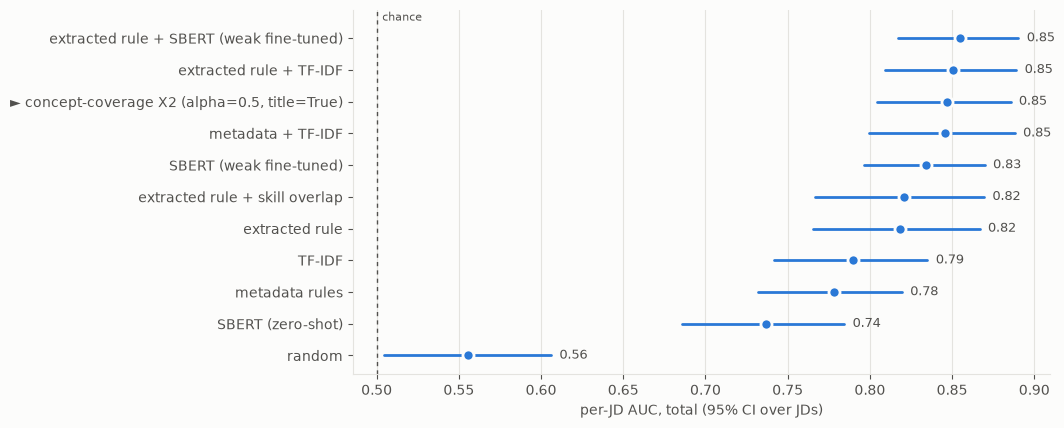

In [11]:
order = table.sort_values("total")
fig, ax = plt.subplots(figsize=(9, 0.34 * len(order) + 1))
reporting.dot_ci(ax, list(order.system)[::-1], list(order.total)[::-1], list(order.lo)[::-1], list(order.hi)[::-1], ref=0.5, ref_label="chance")
ax.set_xlabel("per-JD AUC, total (95% CI over JDs)"); plt.show()

### Paired deltas

Live re-scores of the baselines, then B − A per JD with a JD-resampled CI. The α = 0 control is the same code with the entity term switched off (X2 without the title). Check `generic` and `targeted` agree with the total.

In [12]:
baselines = {"X2 control (alpha=0, no title)": build_model(0.0, use_title=False), "TF-IDF": lexical.Tfidf(VARIANT)}
rows = []
for bname, b in baselines.items():
    b.fit(None); bs = b.score(final_inputs)
    for scope in final_set.SCOPES:
        d = indomain.paired_delta(scores, bs, lab, pairs, "auc", scope, "all", SEED)
        rows.append({"vs": bname, "scope": scope, "Δ AUC (mine − baseline)": d["delta"], "CI": d["ci"], "n_jd": d["n_jd"]})
pd.DataFrame(rows)

,vs,scope,Δ AUC (mine − baseline),CI,n_jd
0,"X2 control (alpha=0, no title)",generic,-0.002654,"[-0.022071, 0.018417]",39
1,"X2 control (alpha=0, no title)",targeted,-0.006036,"[-0.048168, 0.02768]",20
2,"X2 control (alpha=0, no title)",total,-0.003800,"[-0.022846, 0.014417]",59
3,TF-IDF,generic,0.079705,"[0.030203, 0.13326]",39
4,TF-IDF,targeted,0.013375,"[-0.047334, 0.069042]",20
5,TF-IDF,total,0.057220,"[0.01723, 0.098053]",59


### Before you report this

- A model that read labels, `Primary Keyword`, CV `Position` or experience fields is invalid (D46, D53).
- It is `exploratory` here (α was picked on the dev pools, then scored on the final set once). A claim needs the comparison registered in a plan first (rule 8), then `stage1.specs()` and `checks --cold` (D55).
- Cap printed output and never print a CV.